# **Entraînement d'un réseau antagoniste génératif stable**

Nous allons entraîner un GAN stable pour générer des images d'un chiffre manuscrit, en utilisant spécifiquement le chiffre « 8 » du jeu de données MNIST.

Les résultats de ce modèle permettront de créer un GAN stable, utilisable pour des expériences ultérieures, et de définir un profil des images générées ainsi que des courbes d'apprentissage typiques d'un entraînement de GAN stable.

La première étape consiste à définir les modèles.

Le modèle **discriminateur** prend en entrée une image en niveaux de gris de 28×28 et produit une prédiction binaire pour indiquer si l'image est réelle (classe=1) ou fausse (classe=0). Il est mis en œuvre sous la forme d'un réseau de neurones convolutionnel modeste, en suivant les bonnes pratiques de conception de GAN, telles que l'utilisation de la fonction d'activation LeakyReLU avec une pente de 0,2, une sous-échantillonnage avec un stride de 2×2, et l'algorithme adam pour la descente de gradient avec un taux d'apprentissage de 0,0002 et un momentum de 0,5.

La fonction **define_discriminator()** ci-dessous implémente ce modèle, le compile et le retourne. La forme d'entrée de l'image est paramétrée comme argument par défaut pour plus de clarté.

In [13]:
# define the standalone discriminator model
def define_discriminator(in_shape=(28,28,1)):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# downsample to 14x14
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init, input_shape=in_shape))
	model.add(LeakyReLU(alpha=0.2))
	# downsample to 7x7
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# classifier
	model.add(Flatten())
	model.add(Dense(1, activation='sigmoid'))
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
	return model

Le **modèle générateur** prend en entrée un point dans l'espace latent et génère une image en niveaux de gris de 28×28. Cela est réalisé en utilisant une couche entièrement connectée pour interpréter le point dans l'espace latent et fournir des activations suffisantes qui peuvent être redimensionnées en plusieurs copies (ici, 128) d'une version à basse résolution de l'image de sortie (par exemple, 7×7). Ensuite, cette version est upéchantillonnée deux fois, doublant la taille et multipliant par quatre la surface des activations à chaque étape, à l'aide de couches de convolution transposée. Le modèle suit les bonnes pratiques, comme l'utilisation de la fonction d'activation LeakyReLU, d'une taille de noyau proportionnelle à la taille du stride, et de la fonction d'activation tangente hyperbolique (tanh) dans la couche de sortie.

In [2]:
# define the standalone generator model
def define_generator(latent_dim):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# foundation for 7x7 image
	n_nodes = 128 * 7 * 7
	model.add(Dense(n_nodes, kernel_initializer=init, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((7, 7, 128)))
	# upsample to 14x14
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 28x28
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# output 28x28x1
	model.add(Conv2D(1, (7,7), activation='tanh', padding='same', kernel_initializer=init))
	return model

Ensuite, un **modèle GAN** peut être défini en **combinant le modèle générateur et le modèle discriminateur** dans un modèle plus large. Ce modèle global sera utilisé pour entraîner les poids du générateur, en utilisant la sortie et l'erreur calculée par le modèle discriminateur. Le modèle discriminateur est entraîné séparément, et donc, dans ce modèle GAN plus grand, ses poids sont marqués comme non entraînables pour s'assurer que seuls les poids du générateur sont mis à jour. Ce changement n'affecte les poids du discriminateur que lors de l'entraînement du modèle GAN combiné, et non lorsqu'il est entraîné séparément.

Ce modèle GAN prend en entrée un point dans l'espace latent, utilise le générateur pour produire une image, qui est ensuite envoyée au discriminateur pour être classée comme réelle ou fausse.

In [15]:
# define the combined generator and discriminator model, for updating the generator
def define_gan(generator, discriminator):
	# make weights in the discriminator not trainable
	discriminator.trainable = False
	# connect them
	model = Sequential()
	# add generator
	model.add(generator)
	# add the discriminator
	model.add(discriminator)
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt)
	return model

Maintenant que nous avons défini le modèle GAN, il faut l'entraîner. Cependant, avant de commencer l'entraînement, nous avons besoin des données d'entrée.

La première étape consiste à charger et à normaliser le **jeu de données MNIST**. Le jeu de données complet est chargé grâce à la fonction load_data() de Keras, puis un sous-ensemble d'environ 5 000 images est sélectionné, représentant la classe 8, c'est-à-dire des représentations manuscrites du chiffre huit. Ensuite, les valeurs des pixels doivent être mises à l'échelle dans la plage [-1,1] pour correspondre à la sortie du modèle générateur.

La fonction **load_real_samples()** implémente cela, en renvoyant le sous-ensemble chargé et mis à l'échelle du jeu de données MNIST, prêt pour la modélisation.

In [4]:
# load mnist images
def load_real_samples():
	# load dataset
	(trainX, trainy), (_, _) = load_data()
	# expand to 3d, e.g. add channels
	X = expand_dims(trainX, axis=-1)
	# select all of the examples for a given class
	selected_ix = trainy == 8
	X = X[selected_ix]
	# convert from ints to floats
	X = X.astype('float32')
	# scale from [0,255] to [-1,1]
	X = (X - 127.5) / 127.5
	return X

Pour chaque mise à jour du modèle GAN, nous aurons besoin d'un lot (ou d'un demi-lot) d'images réelles provenant du jeu de données. Une manière simple de le faire est de sélectionner un échantillon aléatoire d'images à chaque fois.

La fonction **generate_real_samples()** implémente cette approche. Elle prend le jeu de données préparé en argument, sélectionne et renvoie un échantillon aléatoire d'images, ainsi que leurs étiquettes de classe correspondantes pour le discriminateur, avec la classe spécifiquement définie à 1, indiquant qu'il s'agit d'images réelles.

In [5]:
# select real samples
def generate_real_samples(dataset, n_samples):
	# choose random instances
	ix = randint(0, dataset.shape[0], n_samples)
	# select images
	X = dataset[ix]
	# generate class labels
	y = ones((n_samples, 1))
	return X, y

Ensuite, nous avons besoin d'entrées pour le modèle générateur. Celles-ci sont des points aléatoires issus de l'espace latent, spécifiquement des variables aléatoires suivant une distribution gaussienne.

La fonction **generate_latent_points()** implémente cela. Elle prend la taille de l'espace latent comme argument, ainsi que le nombre de points requis, et les renvoie sous forme de lot d'échantillons d'entrée pour le modèle générateur.

In [6]:
# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
	# generate points in the latent space
	x_input = randn(latent_dim * n_samples)
	# reshape into a batch of inputs for the network
	x_input = x_input.reshape(n_samples, latent_dim)
	return x_input

Ensuite, nous devons utiliser les points dans l'espace latent comme entrée pour le générateur afin de générer de nouvelles images.

La fonction **generate_fake_samples()** ci-dessous met en œuvre ce processus. Elle prend en arguments le modèle de générateur et la taille de l'espace latent, puis génère des points dans cet espace latent pour les utiliser comme entrée du modèle de générateur. La fonction renvoie les images générées ainsi que leur étiquette de classe correspondante pour le modèle discriminateur, spécifiquement la classe=0 pour indiquer qu'elles sont fausses ou générées.

In [7]:
# use the generator to generate n fake examples, with class labels
def generate_fake_samples(generator, latent_dim, n_samples):
	# generate points in latent space
	x_input = generate_latent_points(latent_dim, n_samples)
	# predict outputs
	X = generator.predict(x_input)
	# create class labels
	y = zeros((n_samples, 1))
	return X, y

Nous devons enregistrer les performances du modèle. Peut-être la méthode la plus fiable pour évaluer les performances d'un GAN est d'utiliser le générateur pour créer des images, puis de les examiner et de les évaluer subjectivement.

La fonction **summarize_performance()** ci-dessous prend le modèle de générateur à un moment donné durant l'entraînement et l'utilise pour générer 100 images disposées dans une grille de 10×10, qui sont ensuite tracées et sauvegardées dans un fichier. Le modèle est également enregistré dans un fichier à ce moment-là, au cas où nous souhaiterions l'utiliser ultérieurement pour générer d'autres images.

In [8]:
# generate samples and save as a plot and save the model
def summarize_performance(step, g_model, latent_dim, n_samples=100):
	# prepare fake examples
	X, _ = generate_fake_samples(g_model, latent_dim, n_samples)
	# scale from [-1,1] to [0,1]
	X = (X + 1) / 2.0
	# plot images
	for i in range(10 * 10):
		# define subplot
		pyplot.subplot(10, 10, 1 + i)
		# turn off axis
		pyplot.axis('off')
		# plot raw pixel data
		pyplot.imshow(X[i, :, :, 0], cmap='gray_r')
	# save plot to file
	pyplot.savefig('results_baseline/generated_plot_%03d.png' % (step+1))
	pyplot.close()
	# save the generator model
	g_model.save('results_baseline/model_%03d.h5' % (step+1))

En plus de la qualité des images, il est judicieux de suivre la perte et l'exactitude du modèle au fil du temps.

La perte et la précision de classification pour le discriminateur concernant les échantillons réels et faux peuvent être suivies à chaque mise à jour du modèle, tout comme la perte du générateur. Ces données peuvent ensuite être utilisées pour créer des graphiques linéaires de la perte et de la précision à la fin de l'entraînement.

La fonction **plot_history()** ci-dessous met en œuvre ce suivi et enregistre les résultats dans un fichier.

In [9]:
# create a line plot of loss for the gan and save to file
def plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist):
	# plot loss
	pyplot.subplot(2, 1, 1)
	pyplot.plot(d1_hist, label='d-real')
	pyplot.plot(d2_hist, label='d-fake')
	pyplot.plot(g_hist, label='gen')
	pyplot.legend()
	# plot discriminator accuracy
	pyplot.subplot(2, 1, 2)
	pyplot.plot(a1_hist, label='acc-real')
	pyplot.plot(a2_hist, label='acc-fake')
	pyplot.legend()
	# save plot to file
	pyplot.savefig('results_baseline/plot_line_plot_loss.png')
	pyplot.close()

Nous sommes maintenant prêts à entraîner le modèle GAN.

Le modèle est entraîné pendant 10 époques, un choix arbitraire, car le modèle commence à générer des chiffres « 8 » plausibles après seulement quelques époques. Une taille de lot de 128 échantillons est utilisée, et chaque époque d'entraînement implique environ 45 lots d'échantillons réels et faux, soit un total de 5,851/128 mises à jour du modèle. Le modèle est donc entraîné pendant 10 époques de 45 lots, soit 450 itérations.

Tout d'abord, le modèle discriminateur est mis à jour avec une moitié de lot d'échantillons réels, puis avec une moitié de lot d'échantillons faux, formant ainsi un lot de mises à jour de poids. Ensuite, le générateur est mis à jour via le modèle GAN composite. Il est important de noter que l'étiquette de classe est fixée à 1, ou réel, pour les échantillons générés. Cela permet de mettre à jour le générateur afin d'améliorer la qualité des échantillons générés lors du prochain lot.

La fonction **train()** ci-dessous met en œuvre ce processus, prenant en arguments les modèles définis, le jeu de données et la taille de la dimension latente, tout en paramétrant le nombre d'époques et la taille du lot avec des valeurs par défaut. Le modèle générateur est sauvegardé à la fin de l'entraînement.

Les performances des modèles discriminateur et générateur sont rapportées à chaque itération. Des images échantillons sont générées et sauvegardées à chaque époque, et des graphiques linéaires des performances du modèle sont créés et sauvegardés à la fin de l'entraînement.

In [21]:
# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=10, n_batch=128):
    # calculate the number of batches per epoch
    bat_per_epo = int(dataset.shape[0] / n_batch)
    # calculate the total iterations based on batch and epoch
    n_steps = bat_per_epo * n_epochs
    # calculate the number of samples in half a batch
    half_batch = int(n_batch / 2)
    # prepare lists for storing stats each iteration
    d1_hist, d2_hist, g_hist, a1_hist, a2_hist = list(), list(), list(), list(), list()
    # manually enumerate epochs
    for i in range(n_steps):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator model weights
        d_loss1 = d_model.train_on_batch(X_real, y_real)
        print(f'Discriminator Loss (Real): {d_loss1}')  # Debug print
        d_loss1_value, d_acc1 = d_loss1[0], d_loss1[1] if len(d_loss1) > 1 else (0, 0)

        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
        # update discriminator model weights
        d_loss2 = d_model.train_on_batch(X_fake, y_fake)
        print(f'Discriminator Loss (Fake): {d_loss2}')  # Debug print
        d_loss2_value, d_acc2 = d_loss2[0], d_loss2[1] if len(d_loss2) > 1 else (0, 0)

        # prepare points in latent space as input for the generator
        X_gan = generate_latent_points(latent_dim, n_batch)
        # create inverted labels for the fake samples
        y_gan = ones((n_batch, 1))
        # update the generator via the discriminator's error
        g_loss = gan_model.train_on_batch(X_gan, y_gan)
        print(f'Generator Loss: {g_loss}')  # Debug print
        g_loss_value = g_loss[0]  # Assuming the first element is the loss

        # summarize loss on this batch
        print('>%d, d1=%.3f, d2=%.3f g=%.3f, a1=%d, a2=%d' %
              (i + 1, d_loss1_value, d_loss2_value, g_loss_value, int(100 * d_acc1), int(100 * d_acc2)))

        # record history
        d1_hist.append(d_loss1_value)
        d2_hist.append(d_loss2_value)
        g_hist.append(g_loss_value)
        a1_hist.append(d_acc1)
        a2_hist.append(d_acc2)

        # evaluate the model performance every 'epoch'
        if (i + 1) % bat_per_epo == 0:
            summarize_performance(i, g_model, latent_dim)
    plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist)

Maintenant que toutes les fonctions ont été définies, nous pouvons créer le répertoire où les images et les modèles seront stockés (dans ce cas, results_baseline), créer les modèles, charger le jeu de données et commencer le processus d'entraînement.

In [22]:
# example of training a stable gan for generating a handwritten digit
from os import makedirs
from numpy import expand_dims
from numpy import zeros
from numpy import ones
from numpy.random import randn
from numpy.random import randint
from keras.datasets.mnist import load_data
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import Conv2DTranspose
from keras.layers import LeakyReLU
from keras.initializers import RandomNormal
from matplotlib import pyplot

# make folder for results
makedirs('results_baseline', exist_ok=True)
# size of the latent space
latent_dim = 50
# create the discriminator
discriminator = define_discriminator()
# create the generator
generator = define_generator(latent_dim)
# create the gan
gan_model = define_gan(generator, discriminator)
# load image data
dataset = load_real_samples()
print(dataset.shape)
# train model
train(generator, discriminator, gan_model, dataset, latent_dim)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


(5851, 28, 28, 1)


/usr/local/lib/python3.10/dist-packages/keras/src/backend/tensorflow/trainer.py:75: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Discriminator Loss (Real): [array(0.65919423, dtype=float32), array(1., dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
Discriminator Loss (Fake): [array(0.676203, dtype=float32), array(0.671875, dtype=float32)]
Generator Loss: [array(0.676203, dtype=float32), array(0.676203, dtype=float32), array(0.671875, dtype=float32)]
>1, d1=0.659, d2=0.676 g=0.676, a1=100, a2=67
Discriminator Loss (Real): [array(0.6708968, dtype=float32), array(0.78125, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
Discriminator Loss (Fake): [array(0.67659044, dtype=float32), array(0.5859375, dtype=float32)]
Generator Loss: [array(0.67659044, dtype=float32), array(0.67659044, dtype=float32), array(0.5859375, dtype=float32)]
>2, d1=0.671, d2=0.677 g=0.677, a1=78, a2=58
Discriminator Loss (Real): [array(0.67285424, dtype=float32), array(0.66875, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
Discriminator Loss (Fake): [array(0.676433, dtype=float32), array(0.5572917, dtype=float32)]
Generato

Discriminator Loss (Real): [array(0.7001166, dtype=float32), array(0.509272, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
Discriminator Loss (Fake): [array(0.7009861, dtype=float32), array(0.50373644, dtype=float32)]
Generator Loss: [array(0.7009861, dtype=float32), array(0.7009861, dtype=float32), array(0.50373644, dtype=float32)]
>46, d1=0.700, d2=0.701 g=0.701, a1=50, a2=50
Discriminator Loss (Real): [array(0.7005415, dtype=float32), array(0.5090726, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
Discriminator Loss (Fake): [array(0.70139825, dtype=float32), array(0.5036569, dtype=float32)]
Generator Loss: [array(0.70139825, dtype=float32), array(0.70139825, dtype=float32), array(0.5036569, dtype=float32)]
>47, d1=0.701, d2=0.701 g=0.701, a1=50, a2=50
Discriminator Loss (Real): [array(0.70096153, dtype=float32), array(0.50888157, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
Discriminator Loss (Fake): [array(0.7018027, dtype=float32), array(0.50358075, dtyp

...

Discriminator Loss (Real): [array(0.74210757, dtype=float32), array(0.5018709, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
Discriminator Loss (Fake): [array(0.7424093, dtype=float32), array(0.5007605, dtype=float32)]
Generator Loss: [array(0.7424093, dtype=float32), array(0.7424093, dtype=float32), array(0.5007605, dtype=float32)]
>226, d1=0.742, d2=0.742 g=0.742, a1=50, a2=50
Discriminator Loss (Real): [array(0.7422296, dtype=float32), array(0.5018626, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
Discriminator Loss (Fake): [array(0.7425302, dtype=float32), array(0.50075716, dtype=float32)]
Generator Loss: [array(0.7425302, dtype=float32), array(0.7425302, dtype=float32), array(0.50075716, dtype=float32)]
>227, d1=0.742, d2=0.743 g=0.743, a1=50, a2=50
Discriminator Loss (Real): [array(0.7423502, dtype=float32), array(0.5018544, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
Discriminator Loss (Fake): [array(0.7426491, dtype=float32), array(0.5007538, dtype=

Discriminator Loss (Real): [array(0.74685025, dtype=float32), array(0.5015596, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
Discriminator Loss (Fake): [array(0.74710166, dtype=float32), array(0.50063425, dtype=float32)]
Generator Loss: [array(0.74710166, dtype=float32), array(0.74710166, dtype=float32), array(0.50063425, dtype=float32)]
>271, d1=0.747, d2=0.747 g=0.747, a1=50, a2=50
Discriminator Loss (Real): [array(0.7469402, dtype=float32), array(0.5015539, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
Discriminator Loss (Fake): [array(0.74719113, dtype=float32), array(0.50063187, dtype=float32)]
Generator Loss: [array(0.74719113, dtype=float32), array(0.74719113, dtype=float32), array(0.50063187, dtype=float32)]
>272, d1=0.747, d2=0.747 g=0.747, a1=50, a2=50
Discriminator Loss (Real): [array(0.74703115, dtype=float32), array(0.5015482, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
Discriminator Loss (Fake): [array(0.7472809, dtype=float32), array(0.500629

Discriminator Loss (Real): [array(0.7506944, dtype=float32), array(0.5013372, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
Discriminator Loss (Fake): [array(0.75091463, dtype=float32), array(0.5005439, dtype=float32)]
Generator Loss: [array(0.75091463, dtype=float32), array(0.75091463, dtype=float32), array(0.5005439, dtype=float32)]
>316, d1=0.751, d2=0.751 g=0.751, a1=50, a2=50
Discriminator Loss (Real): [array(0.7507703, dtype=float32), array(0.50133294, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
Discriminator Loss (Fake): [array(0.7509911, dtype=float32), array(0.50054216, dtype=float32)]
Generator Loss: [array(0.7509911, dtype=float32), array(0.7509911, dtype=float32), array(0.50054216, dtype=float32)]
>317, d1=0.751, d2=0.751 g=0.751, a1=50, a2=50
Discriminator Loss (Real): [array(0.75085, dtype=float32), array(0.50132877, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
Discriminator Loss (Fake): [array(0.75107163, dtype=float32), array(0.5005405, dty

Discriminator Loss (Real): [array(0.75399977, dtype=float32), array(0.5011703, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
Discriminator Loss (Fake): [array(0.7541968, dtype=float32), array(0.5004761, dtype=float32)]
Generator Loss: [array(0.7541968, dtype=float32), array(0.7541968, dtype=float32), array(0.5004761, dtype=float32)]
>361, d1=0.754, d2=0.754 g=0.754, a1=50, a2=50
Discriminator Loss (Real): [array(0.75406784, dtype=float32), array(0.501167, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
Discriminator Loss (Fake): [array(0.7542643, dtype=float32), array(0.5004748, dtype=float32)]
Generator Loss: [array(0.7542643, dtype=float32), array(0.7542643, dtype=float32), array(0.5004748, dtype=float32)]
>362, d1=0.754, d2=0.754 g=0.754, a1=50, a2=50
Discriminator Loss (Real): [array(0.75413555, dtype=float32), array(0.5011638, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
Discriminator Loss (Fake): [array(0.7543318, dtype=float32), array(0.5004735, dtype=f

Discriminator Loss (Real): [array(0.75682765, dtype=float32), array(0.5010404, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
Discriminator Loss (Fake): [array(0.7570049, dtype=float32), array(0.5004233, dtype=float32)]
Generator Loss: [array(0.7570049, dtype=float32), array(0.7570049, dtype=float32), array(0.5004233, dtype=float32)]
>406, d1=0.757, d2=0.757 g=0.757, a1=50, a2=50
Discriminator Loss (Real): [array(0.75688636, dtype=float32), array(0.50103784, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Discriminator Loss (Fake): [array(0.75706327, dtype=float32), array(0.5004223, dtype=float32)]
Generator Loss: [array(0.75706327, dtype=float32), array(0.75706327, dtype=float32), array(0.5004223, dtype=float32)]
>407, d1=0.757, d2=0.757 g=0.757, a1=50, a2=50
Discriminator Loss (Real): [array(0.75694424, dtype=float32), array(0.5010353, dtype=float32)]
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
Discriminator Loss (Fake): [array(0.75712055, dtype=float32), array(0.5004213, d

Vos résultats spécifiques varieront en raison de la nature stochastique de l'algorithme d'apprentissage. Néanmoins, la structure générale de l'entraînement devrait être très similaire.

Tout d'abord, la perte et la précision du discriminateur, ainsi que la perte du modèle de générateur, sont rapportées à la console à chaque itération de la boucle d'entraînement.

C'est important. Un GAN stable aura une perte du discriminateur autour de 0,5, généralement entre 0,5 et peut-être jusqu'à 0,7 ou 0,8. La perte du générateur est généralement plus élevée et peut se situer autour de 1,0, 1,5, 2,0, voire plus.

La précision du discriminateur sur les images réelles et générées (fausses) ne sera pas de 50 %, mais devrait typiquement se situer autour de 70 % à 80 %.

Pour les deux modèles, le comportement est susceptible de commencer de manière erratique et de fluctuer beaucoup avant que le modèle ne converge vers un équilibre stable.

**Des graphiques linéaires pour la perte et la précision sont créés et sauvegardés à la fin de l'exécution.**
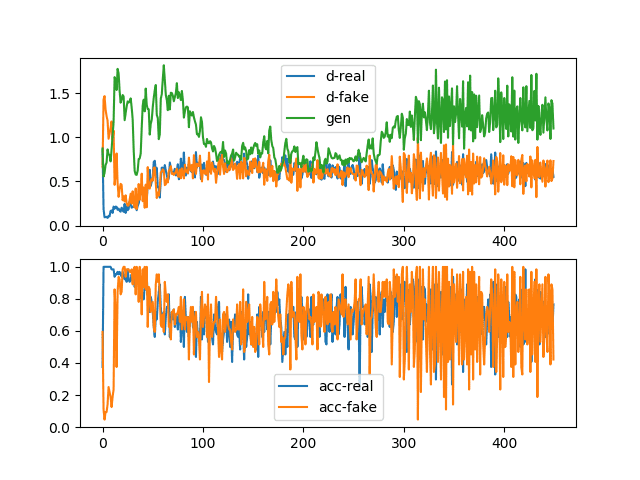

La figure contient deux sous-graphes. Le premier sous-graphe montre les graphiques linéaires pour la perte du discriminateur sur les images réelles (bleu), la perte du discriminateur sur les images générées (orange) et la perte du générateur sur les images générées (vert).

On observe que les trois pertes sont quelque peu erratiques au début de l'exécution avant de se stabiliser autour de l'époque 100 à 300. Les pertes restent stables après cela, bien que la variance augmente.

Ceci est un exemple de perte normale ou attendue pendant l'entraînement. En effet, la perte du discriminateur pour les échantillons réels et faux est à peu près la même, autour de 0,5, tandis que la perte du générateur est légèrement plus élevée, entre 0,5 et 2,0. Si le modèle de générateur est capable de générer des images plausibles, on s'attend à ce que ces images aient été produites entre les époques 100 et 300 et probablement aussi entre 300 et 450.

Le second sous-graphe montre un graphique linéaire de la précision du discriminateur sur les images réelles (bleu) et fausses (orange) durant l'entraînement. Nous voyons une structure similaire à celle du sous-graphe de la perte, à savoir que la précision commence assez différente entre les deux types d'images, puis se stabilise entre les époques 100 et 300 autour de 70 % à 80 %, et reste stable par la suite, bien qu'avec une variance accrue.

Les échelles de temps (par exemple, le nombre d'itérations ou d'époques d'entraînement) pour ces motifs et valeurs absolues varieront selon les problèmes et les types de modèles GAN, bien que le graphique fournisse une bonne base pour ce à quoi s'attendre lors de l'entraînement d'un modèle GAN stable.

Enfin, nous pouvons examiner des échantillons d'images générées. Notez que nous générons des images en utilisant une inversion de la carte des couleurs en niveaux de gris, ce qui signifie que la figure blanche normale sur un fond noir est inversée en une figure noire sur un fond blanc. Cela a été fait pour faciliter la révision des figures générées.

Comme on pourrait s'y attendre, les échantillons d'images générées avant l'époque 100 sont relativement de mauvaise qualité.

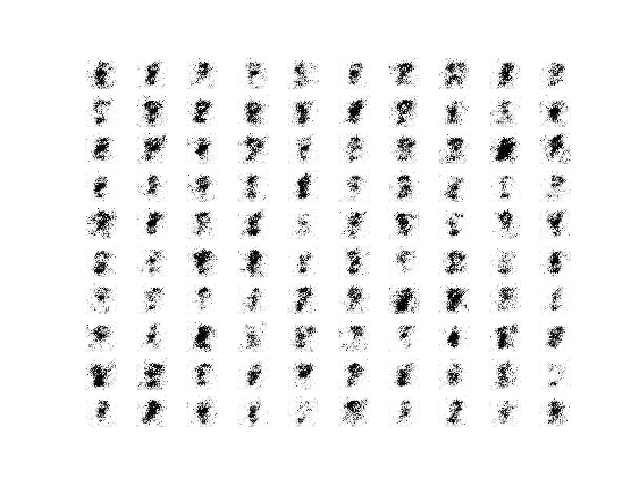

Les échantillons d'images générées entre les époques 100 et 300 sont plausibles et présentent peut-être la meilleure qualité.

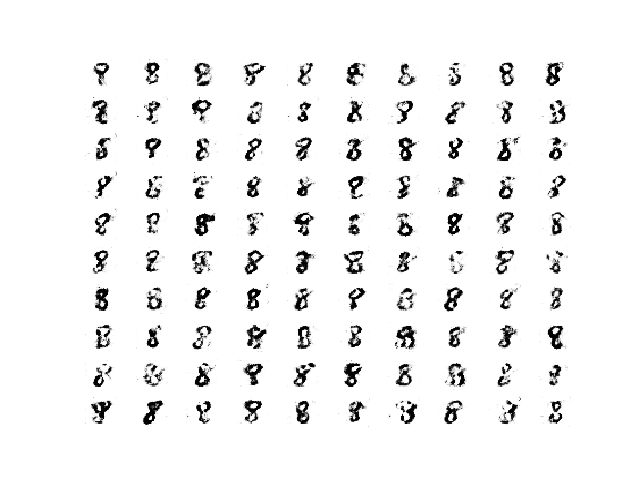

Les échantillons d'images générées après l'époque 300 restent plausibles, bien qu'ils aient peut-être plus de bruit, par exemple du bruit de fond.

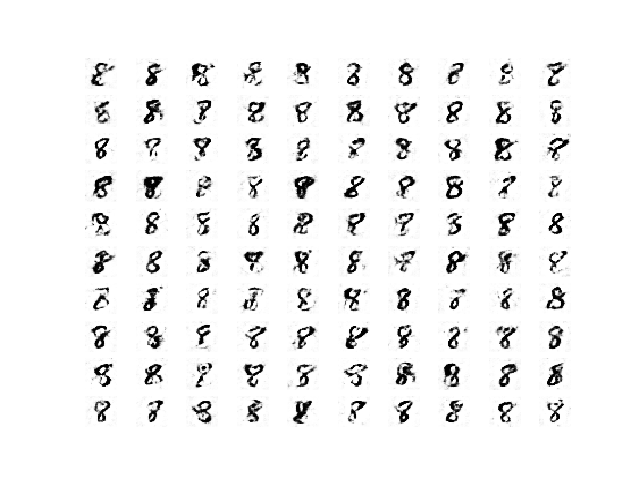

Ces résultats sont importants, car ils soulignent que la qualité générée peut et varie au cours de l'exécution, même après que le processus d'entraînement devienne stable.

De plus, davantage d'itérations d'entraînement, au-delà d'un certain point de stabilité d'entraînement, peuvent ou non aboutir à des images de meilleure qualité.

Nous pouvons résumer ces observations pour l'entraînement d'un GAN stable comme suit :

*   La perte du discriminateur sur les images réelles et fausses est censée se situer autour de 0,5.
*   La perte du générateur sur les images fausses est censée se situer entre 0,5 et 2,0.
*   La précision du discriminateur sur les images réelles et fausses est censée se situer autour de 80 %.
*   La variance de la perte du générateur et du discriminateur est censée rester modeste.
*   Le générateur est censé produire ses images de la plus haute qualité pendant une période de stabilité.
*   La stabilité d'entraînement peut dégénérer en périodes de perte à forte variance et en images générées de qualité inférieure.

fausses est censée se situer autour de 0,5.
La perte du générateur sur les images fausses est censée se situer entre 0,5 et 2,0.
La précision du discriminateur sur les images réelles et fausses est censée se situer autour de 80 %.
La variance de la perte du générateur et du discriminateur est censée rester modeste.
Le générateur est censé produire ses images de la plus haute qualité pendant une période de stabilité.
La stabilité d'entraînement peut dégénérer en périodes de perte à forte variance et en images générées de qualité inférieure.
Maintenant que nous avons un modèle GAN stable, nous pouvons envisager de le modifier pour produire des cas d'échec spécifiques.

Il existe deux cas d'échec courants lors de l'entraînement de modèles GAN sur de nouveaux problèmes : l'effondrement de mode (mode collapse) et l'échec de convergence.

# **Identifier un Mode Collapse dans un GAN**

Un **mode collapse** fait référence à un modèle de générateur qui n'est capable de générer qu'un seul ou un petit sous-ensemble de résultats ou modes différents.

Ce phénomène peut être identifié en examinant un grand échantillon d'images générées. Les images montreront peu de diversité, avec la même image ou un petit sous-ensemble d'images identiques répétées plusieurs fois.

Un mode collapse peut également être identifié en consultant le graphique de la perte du modèle. Ce graphique affichera des oscillations de la perte au fil du temps, notamment dans le modèle générateur, lorsque celui-ci est mis à jour et passe de la génération d'un mode à un autre, avec une perte différente.

Nous pouvons induire un mode collapse dans notre GAN stable de plusieurs manières. Peut-être la plus fiable est de restreindre la taille de la dimension latente directement, forçant le modèle à ne générer qu'un petit sous-ensemble de résultats plausibles.

Plus précisément, la variable latent_dim peut être modifiée de 100 à 1, et l'expérience peut être relancée.

In [ ]:
# size of the latent space
latent_dim = 1

In [35]:
# example of training an unstable gan for generating a handwritten digit
from os import makedirs
from numpy import expand_dims
from numpy import zeros
from numpy import ones
from numpy.random import randn
from numpy.random import randint
from keras.datasets.mnist import load_data
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import Conv2DTranspose
from keras.layers import LeakyReLU
from keras.initializers import RandomNormal
from matplotlib import pyplot

# define the standalone discriminator model
def define_discriminator(in_shape=(28,28,1)):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# downsample to 14x14
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init, input_shape=in_shape))
	model.add(LeakyReLU(alpha=0.2))
	# downsample to 7x7
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# classifier
	model.add(Flatten())
	model.add(Dense(1, activation='sigmoid'))
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
	return model

# define the standalone generator model
def define_generator(latent_dim):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# foundation for 7x7 image
	n_nodes = 128 * 7 * 7
	model.add(Dense(n_nodes, kernel_initializer=init, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((7, 7, 128)))
	# upsample to 14x14
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 28x28
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# output 28x28x1
	model.add(Conv2D(1, (7,7), activation='tanh', padding='same', kernel_initializer=init))
	return model

# define the combined generator and discriminator model, for updating the generator
def define_gan(generator, discriminator):
	# make weights in the discriminator not trainable
	discriminator.trainable = False
	# connect them
	model = Sequential()
	# add generator
	model.add(generator)
	# add the discriminator
	model.add(discriminator)
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt)
	return model

# load mnist images
def load_real_samples():
	# load dataset
	(trainX, trainy), (_, _) = load_data()
	# expand to 3d, e.g. add channels
	X = expand_dims(trainX, axis=-1)
	# select all of the examples for a given class
	selected_ix = trainy == 8
	X = X[selected_ix]
	# convert from ints to floats
	X = X.astype('float32')
	# scale from [0,255] to [-1,1]
	X = (X - 127.5) / 127.5
	return X

# # select real samples
def generate_real_samples(dataset, n_samples):
	# choose random instances
	ix = randint(0, dataset.shape[0], n_samples)
	# select images
	X = dataset[ix]
	# generate class labels
	y = ones((n_samples, 1))
	return X, y

# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
	# generate points in the latent space
	x_input = randn(latent_dim * n_samples)
	# reshape into a batch of inputs for the network
	x_input = x_input.reshape(n_samples, latent_dim)
	return x_input

# use the generator to generate n fake examples, with class labels
def generate_fake_samples(generator, latent_dim, n_samples):
	# generate points in latent space
	x_input = generate_latent_points(latent_dim, n_samples)
	# predict outputs
	X = generator.predict(x_input)
	# create class labels
	y = zeros((n_samples, 1))
	return X, y

# generate samples and save as a plot and save the model
def summarize_performance(step, g_model, latent_dim, n_samples=100):
	# prepare fake examples
	X, _ = generate_fake_samples(g_model, latent_dim, n_samples)
	# scale from [-1,1] to [0,1]
	X = (X + 1) / 2.0
	# plot images
	for i in range(10 * 10):
		# define subplot
		pyplot.subplot(10, 10, 1 + i)
		# turn off axis
		pyplot.axis('off')
		# plot raw pixel data
		pyplot.imshow(X[i, :, :, 0], cmap='gray_r')
	# save plot to file
	pyplot.savefig('results_collapse/generated_plot_%03d.png' % (step+1))
	pyplot.close()
	# save the generator model
	g_model.save('results_collapse/model_%03d.h5' % (step+1))

# create a line plot of loss for the gan and save to file
def plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist):
	# plot loss
	pyplot.subplot(2, 1, 1)
	pyplot.plot(d1_hist, label='d-real')
	pyplot.plot(d2_hist, label='d-fake')
	pyplot.plot(g_hist, label='gen')
	pyplot.legend()
	# plot discriminator accuracy
	pyplot.subplot(2, 1, 2)
	pyplot.plot(a1_hist, label='acc-real')
	pyplot.plot(a2_hist, label='acc-fake')
	pyplot.legend()
	# save plot to file
	pyplot.savefig('results_collapse/plot_line_plot_loss.png')
	pyplot.close()

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=10, n_batch=128):
    # calculate the number of batches per epoch
    bat_per_epo = int(dataset.shape[0] / n_batch)
    # calculate the total iterations based on batch and epoch
    n_steps = bat_per_epo * n_epochs
    # calculate the number of samples in half a batch
    half_batch = int(n_batch / 2)
    # prepare lists for storing stats each iteration
    d1_hist, d2_hist, g_hist, a1_hist, a2_hist = list(), list(), list(), list(), list()

    # manually enumerate epochs
    for i in range(n_steps):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator model weights
        d_loss1, d_acc1 = d_model.train_on_batch(X_real, y_real)

        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
        # update discriminator model weights
        d_loss2, d_acc2 = d_model.train_on_batch(X_fake, y_fake)

        # prepare points in latent space as input for the generator
        X_gan = generate_latent_points(latent_dim, n_batch)
        # create inverted labels for the fake samples
        y_gan = ones((n_batch, 1))
        # update the generator via the discriminator's error
        g_loss = gan_model.train_on_batch(X_gan, y_gan)

        # Extract the loss values if they are lists
        if isinstance(g_loss, list):
            g_loss_value = g_loss[0]  # Assuming the first element is the loss value
        else:
            g_loss_value = g_loss

        # summarize loss on this batch
        print('>%d, d1=%.3f, d2=%.3f g=%.3f, a1=%d, a2=%d' %
              (i + 1, d_loss1, d_loss2, g_loss_value, int(100 * d_acc1), int(100 * d_acc2)))

        # record history
        d1_hist.append(d_loss1)
        d2_hist.append(d_loss2)
        g_hist.append(g_loss_value)
        a1_hist.append(d_acc1)
        a2_hist.append(d_acc2)

        # evaluate the model performance every 'epoch'
        if (i + 1) % bat_per_epo == 0:
            summarize_performance(i, g_model, latent_dim)

    # plot the history
    plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist)

# make folder for results
makedirs('results_collapse', exist_ok=True)
# size of the latent space
latent_dim = 1
# create the discriminator
discriminator = define_discriminator()
# create the generator
generator = define_generator(latent_dim)
# create the gan
gan_model = define_gan(generator, discriminator)
# load image data
dataset = load_real_samples()
print(dataset.shape)
# train model
train(generator, discriminator, gan_model, dataset, latent_dim)

(5851, 28, 28, 1)
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>1, d1=0.682, d2=0.688 g=0.688, a1=85, a2=64
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
>2, d1=0.686, d2=0.688 g=0.688, a1=73, a2=55
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
>3, d1=0.687, d2=0.688 g=0.688, a1=61, a2=51
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
>4, d1=0.687, d2=0.688 g=0.688, a1=54, a2=47
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
>5, d1=0.688, d2=0.688 g=0.688, a1=50, a2=45
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>6, d1=0.688, d2=0.688 g=0.688, a1=50, a2=45
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>7, d1=0.688, d2=0.688 g=0.688, a1=48, a2=45
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>8, d1=0.688, d2=0.688 g=0.688, a1=48, a2=45
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step
>9, d1=0.688, d2=0.688 g=0.688, a1=46, a2=44
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>10, d1=0.688, d2=0.688 g=0.688, a1=46, a2=44
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
>11, d1=0.688, d2=0.688 g=0.688, a1=46, a2=44
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
>12, d1=0.688, d2

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
>46, d1=0.700, d2=0.701 g=0.701, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
>47, d1=0.701, d2=0.701 g=0.701, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
>48, d1=0.701, d2=0.702 g=0.702, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>49, d1=0.702, d2=0.702 g=0.702, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
>50, d1=0.702, d2=0.703 g=0.703, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
>51, d1=0.703, d2=0.703 g=0.703, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>52, d1=0.703, d2=0.704 g=0.704, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
>53, d1=0.704, d2=0.704 g=0.704, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
>54, d1=0.704, d2=0.705 g=0.705, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
>55, d1=0.705, d2=0.705 g=0.705, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
>56, d1=0.705, d2=0.706 g=0.706, a1=44, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>57, d1=0.705, d2=0.706 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>91, d1=0.721, d2=0.722 g=0.722, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
>92, d1=0.722, d2=0.722 g=0.722, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>93, d1=0.722, d2=0.723 g=0.723, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
>94, d1=0.722, d2=0.723 g=0.723, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
>95, d1=0.723, d2=0.724 g=0.724, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>96, d1=0.723, d2=0.724 g=0.724, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>97, d1=0.724, d2=0.724 g=0.724, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>98, d1=0.724, d2=0.725 g=0.725, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
>99, d1=0.725, d2=0.725 g=0.725, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 215ms/step
>100, d1=0.725, d2=0.726 g=0.726, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 276ms/step
>101, d1=0.725, d2=0.726 g=0.726, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
>102, d1=0.726, d2=0.726

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>136, d1=0.738, d2=0.739 g=0.739, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
>137, d1=0.739, d2=0.739 g=0.739, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
>138, d1=0.739, d2=0.740 g=0.740, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 219ms/step
>139, d1=0.739, d2=0.740 g=0.740, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 252ms/step
>140, d1=0.740, d2=0.740 g=0.740, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
>141, d1=0.740, d2=0.741 g=0.741, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
>142, d1=0.740, d2=0.741 g=0.741, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
>143, d1=0.741, d2=0.741 g=0.741, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
>144, d1=0.741, d2=0.741 g=0.741, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
>145, d1=0.741, d2=0.742 g=0.742, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>146, d1=0.741, d2=0.742 g=0.742, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>147, d1=0.742,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
>181, d1=0.751, d2=0.751 g=0.751, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>182, d1=0.751, d2=0.752 g=0.752, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
>183, d1=0.751, d2=0.752 g=0.752, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
>184, d1=0.752, d2=0.752 g=0.752, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
>185, d1=0.752, d2=0.752 g=0.752, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
>186, d1=0.752, d2=0.753 g=0.753, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>187, d1=0.752, d2=0.753 g=0.753, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
>188, d1=0.753, d2=0.753 g=0.753, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
>189, d1=0.753, d2=0.753 g=0.753, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>190, d1=0.753, d2=0.754 g=0.754, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>191, d1=0.753, d2=0.754 g=0.754, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
>192, d1=0.754,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
>226, d1=0.761, d2=0.761 g=0.761, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
>227, d1=0.761, d2=0.761 g=0.761, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>228, d1=0.761, d2=0.761 g=0.761, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>229, d1=0.761, d2=0.762 g=0.762, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>230, d1=0.761, d2=0.762 g=0.762, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>231, d1=0.762, d2=0.762 g=0.762, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
>232, d1=0.762, d2=0.762 g=0.762, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
>233, d1=0.762, d2=0.762 g=0.762, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>234, d1=0.762, d2=0.763 g=0.763, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
>235, d1=0.762, d2=0.763 g=0.763, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
>236, d1=0.763, d2=0.763 g=0.763, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>237, d1=0.763,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
>271, d1=0.768, d2=0.768 g=0.768, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>272, d1=0.768, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>273, d1=0.768, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>274, d1=0.769, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
>275, d1=0.769, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
>276, d1=0.769, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
>277, d1=0.769, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>278, d1=0.769, d2=0.769 g=0.769, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>279, d1=0.769, d2=0.770 g=0.770, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
>280, d1=0.769, d2=0.770 g=0.770, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
>281, d1=0.770, d2=0.770 g=0.770, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
>282, d1=0.770,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
>316, d1=0.774, d2=0.774 g=0.774, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
>317, d1=0.774, d2=0.774 g=0.774, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
>318, d1=0.774, d2=0.774 g=0.774, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
>319, d1=0.774, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>320, d1=0.774, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
>321, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>322, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
>323, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>324, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
>325, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
>326, d1=0.775, d2=0.775 g=0.775, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
>327, d1=0.775,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
>361, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>362, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>363, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
>364, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
>365, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
>366, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>367, d1=0.779, d2=0.779 g=0.779, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>368, d1=0.779, d2=0.780 g=0.780, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
>369, d1=0.779, d2=0.780 g=0.780, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>370, d1=0.779, d2=0.780 g=0.780, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>371, d1=0.780, d2=0.780 g=0.780, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
>372, d1=0.780,

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
>406, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
>407, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
>408, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
>409, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>410, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
>411, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step
>412, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>413, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
>414, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
>415, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
>416, d1=0.783, d2=0.783 g=0.783, a1=43, a2=43
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
>417, d1=0.783,

Dans ce cas, la perte du discriminateur se situe dans une plage raisonnable, bien que celle du générateur varie beaucoup. L'exactitude du discriminateur montre également des valeurs élevées, souvent autour de 100 %, ce qui signifie que, pour de nombreux lots, il a une capacité parfaite à identifier les exemples réels ou faux, ce qui est un mauvais signe pour la qualité ou la diversité des images.

Dans le premier sous-graphe, nous pouvons voir la perte du générateur (en vert) oscillant entre des valeurs raisonnables et élevées au fil du temps, avec une période d'environ 25 mises à jour du modèle (lots). Nous pouvons également observer quelques petites oscillations dans la perte du discriminateur sur les échantillons réels et faux (en orange et bleu).

Dans le deuxième sous-graphe, la précision de classification du discriminateur pour identifier les images fausses reste élevée tout au long de l'exécution. Cela suggère que le générateur est peu performant pour générer des exemples d'une manière cohérente, ce qui facilite l'identification des images fausses par le discriminateur.

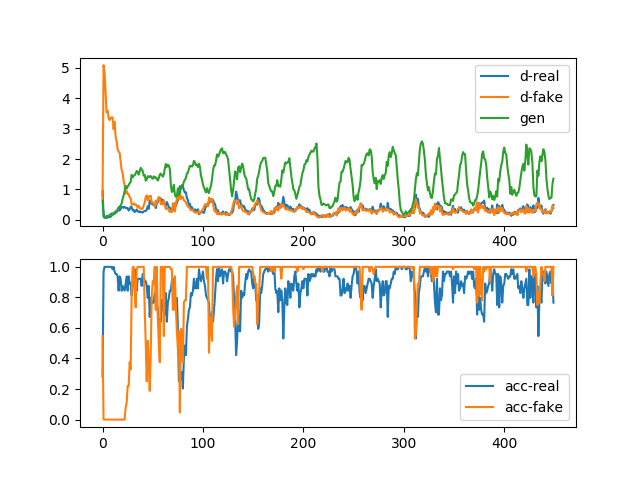

L'examen des images générées montre la caractéristique attendue de le mode collapse, à savoir de nombreux exemples générés identiques, quelle que soit la position d'entrée dans l'espace latent. Nous avons délibérément réduit la dimensionnalité de l'espace latent pour forcer cet effet.

J'ai choisi un exemple d'images générées pour illustrer cela clairement. On n'aperçoit que quelques types de figures huit dans l'image, l'une penchée à gauche, l'autre à droite, et une troisième se tenant droite avec un flou. J'ai entouré certaines des exemples similaires dans l'image ci-dessous pour rendre cela plus évident.

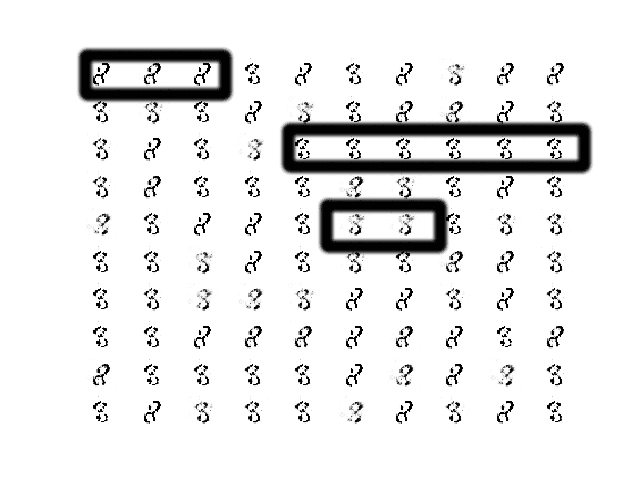

Le mode collapse est moins courant pendant l'entraînement, compte tenu des résultats du modèle DCGAN et de la configuration d'entraînement.

En résumé, vous pouvez identifier un mode collapse de la manière suivante :

*    La perte du générateur, et probablement celle du discriminateur, devrait osciller dans le temps.
*    Le modèle générateur est censé produire des images de sortie identiques à partir de différents points dans l'espace latent.

# **Identifier l'échec de convergence dans un GAN**

L'une des défaillances les plus courantes lors de l'entraînement d'un GAN est l'échec à la convergence.

Généralement, un réseau de neurones ne parvient pas à converger lorsque la perte du modèle ne se stabilise pas au cours du processus d'entraînement. Dans le cas d'un GAN, un échec à la convergence fait référence à l'incapacité de trouver un équilibre entre le discriminateur et le générateur.

Vous pourrez probablement identifier ce type de défaillance si la perte du discriminateur est tombée à zéro ou près de zéro. Dans certains cas, la perte du générateur peut également augmenter et continuer d'augmenter pendant la même période.

Ce type de perte est le plus souvent causé par le fait que le générateur produit des images de mauvaise qualité que le discriminateur peut facilement identifier.

Cette défaillance peut se produire au début de l'exécution et se poursuivre tout au long de l'entraînement, auquel cas il est conseillé d'arrêter le processus d'entraînement. Pour certains GAN instables, il est possible que le GAN entre dans ce mode de défaillance pendant plusieurs mises à jour de lot, voire plusieurs époques, puis se rétablisse.

Il existe de nombreuses façons de dégrader notre GAN stable pour provoquer une défaillance de convergence, telles que la modification d'un ou des deux modèles pour avoir une capacité insuffisante, **le changement de l'algorithme d'optimisation Adam pour être trop agressif**, et l'utilisation de tailles de noyau (kernel sizes) très grandes ou très petites dans les modèles.

Dans ce cas, nous mettrons à jour l'exemple pour combiner les échantillons réels et faux lors de la mise à jour du discriminateur. Ce changement simple consistera à utiliser la fonction vstack() de NumPy pour combiner les échantillons réels et faux, puis d'appeler la fonction train_on_batch() pour mettre à jour le modèle du discriminateur. Le résultat sera également une seule perte et des scores de précision, ce qui signifie que le rapport de performance du modèle devra également être mis à jour.

In [1]:
# example of training an unstable gan for generating a handwritten digit
from os import makedirs
from numpy import expand_dims
from numpy import zeros
from numpy import ones
from numpy import vstack
from numpy.random import randn
from numpy.random import randint
from keras.datasets.mnist import load_data
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import Conv2DTranspose
from keras.layers import LeakyReLU
from keras.initializers import RandomNormal
from matplotlib import pyplot

# define the standalone discriminator model
def define_discriminator(in_shape=(28,28,1)):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# downsample to 14x14
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init, input_shape=in_shape))
	model.add(LeakyReLU(alpha=0.2))
	# downsample to 7x7
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# classifier
	model.add(Flatten())
	model.add(Dense(1, activation='sigmoid'))
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
	return model

# define the standalone generator model
def define_generator(latent_dim):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# foundation for 7x7 image
	n_nodes = 128 * 7 * 7
	model.add(Dense(n_nodes, kernel_initializer=init, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((7, 7, 128)))
	# upsample to 14x14
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 28x28
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# output 28x28x1
	model.add(Conv2D(1, (7,7), activation='tanh', padding='same', kernel_initializer=init))
	return model

# define the combined generator and discriminator model, for updating the generator
def define_gan(generator, discriminator):
	# make weights in the discriminator not trainable
	discriminator.trainable = False
	# connect them
	model = Sequential()
	# add generator
	model.add(generator)
	# add the discriminator
	model.add(discriminator)
	# compile model
	opt = Adam(learning_rate=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt)
	return model

# load mnist images
def load_real_samples():
	# load dataset
	(trainX, trainy), (_, _) = load_data()
	# expand to 3d, e.g. add channels
	X = expand_dims(trainX, axis=-1)
	# select all of the examples for a given class
	selected_ix = trainy == 8
	X = X[selected_ix]
	# convert from ints to floats
	X = X.astype('float32')
	# scale from [0,255] to [-1,1]
	X = (X - 127.5) / 127.5
	return X

# # select real samples
def generate_real_samples(dataset, n_samples):
	# choose random instances
	ix = randint(0, dataset.shape[0], n_samples)
	# select images
	X = dataset[ix]
	# generate class labels
	y = ones((n_samples, 1))
	return X, y

# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
	# generate points in the latent space
	x_input = randn(latent_dim * n_samples)
	# reshape into a batch of inputs for the network
	x_input = x_input.reshape(n_samples, latent_dim)
	return x_input

# use the generator to generate n fake examples, with class labels
def generate_fake_samples(generator, latent_dim, n_samples):
	# generate points in latent space
	x_input = generate_latent_points(latent_dim, n_samples)
	# predict outputs
	X = generator.predict(x_input)
	# create class labels
	y = zeros((n_samples, 1))
	return X, y

# generate samples and save as a plot and save the model
def summarize_performance(step, g_model, latent_dim, n_samples=100):
	# prepare fake examples
	X, _ = generate_fake_samples(g_model, latent_dim, n_samples)
	# scale from [-1,1] to [0,1]
	X = (X + 1) / 2.0
	# plot images
	for i in range(10 * 10):
		# define subplot
		pyplot.subplot(10, 10, 1 + i)
		# turn off axis
		pyplot.axis('off')
		# plot raw pixel data
		pyplot.imshow(X[i, :, :, 0], cmap='gray_r')
	# save plot to file
	pyplot.savefig('results_convergence/generated_plot_%03d.png' % (step+1))
	pyplot.close()
	# save the generator model
	g_model.save('results_convergence/model_%03d.h5' % (step+1))

# create a line plot of loss for the gan and save to file
def plot_history(d_hist, g_hist, a_hist):
	# plot loss
	pyplot.subplot(2, 1, 1)
	pyplot.plot(d_hist, label='dis')
	pyplot.plot(g_hist, label='gen')
	pyplot.legend()
	# plot discriminator accuracy
	pyplot.subplot(2, 1, 2)
	pyplot.plot(a_hist, label='acc')
	pyplot.legend()
	# save plot to file
	pyplot.savefig('results_convergence/plot_line_plot_loss.png')
	pyplot.close()

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=10, n_batch=128):
    # calculate the number of batches per epoch
    bat_per_epo = int(dataset.shape[0] / n_batch)
    # calculate the total iterations based on batch and epoch
    n_steps = bat_per_epo * n_epochs
    # calculate the number of samples in half a batch
    half_batch = int(n_batch / 2)
    # prepare lists for storing stats each iteration
    d_hist, g_hist, a_hist = list(), list(), list()
    # manually enumerate epochs
    for i in range(n_steps):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
        # combine into one batch
        X, y = vstack((X_real, X_fake)), vstack((y_real, y_fake))
        # update discriminator model weights
        d_loss, d_acc = d_model.train_on_batch(X, y)
        # prepare points in latent space as input for the generator
        X_gan = generate_latent_points(latent_dim, n_batch)
        # create inverted labels for the fake samples
        y_gan = ones((n_batch, 1))
        # update the generator via the discriminator's error
        g_loss = gan_model.train_on_batch(X_gan, y_gan)

        # Résoudre l'erreur ici
        if isinstance(g_loss, list):  # Vérifiez si g_loss est une liste
            g_loss_value = g_loss[0]  # Récupérer la première valeur de la liste
        else:
            g_loss_value = g_loss

        # Imprimer les résultats
        print('>%d, d=%.3f, g=%.3f, a=%d' % (i+1, d_loss, g_loss_value, int(100*d_acc)))
        # record history
        d_hist.append(d_loss)
        g_hist.append(g_loss_value)  # Utiliser la valeur de perte récupérée
        a_hist.append(d_acc)
        # evaluate the model performance every 'epoch'
        if (i+1) % bat_per_epo == 0:
            summarize_performance(i, g_model, latent_dim)
    plot_history(d_hist, g_hist, a_hist)

# make folder for results
makedirs('results_convergence', exist_ok=True)
# size of the latent space
latent_dim = 50
# create the discriminator
discriminator = define_discriminator()
# create the generator
generator = define_generator(latent_dim)
# create the gan
gan_model = define_gan(generator, discriminator)
# load image data
dataset = load_real_samples()
print(dataset.shape)
# train model
train(generator, discriminator, gan_model, dataset, latent_dim)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(5851, 28, 28, 1)
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


/usr/local/lib/python3.10/dist-packages/keras/src/backend/tensorflow/trainer.py:75: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


>1, d=0.699, g=0.699, a=44
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>2, d=0.698, g=0.698, a=30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


>3, d=0.698, g=0.698, a=22
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>4, d=0.698, g=0.698, a=18
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>5, d=0.698, g=0.698, a=15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>6, d=0.699, g=0.699, a=13
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>7, d=0.699, g=0.699, a=12
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>8, d=0.699, g=0.699, a=11
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>9, d=0.700, g=0.700, a=10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>10, d=0.700, g=0.700, a=10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>11, d=0.700, g=0.700, a=9
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>12, d=0.701, g=0.701, a=8
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>13, d=0.701, g=0.701, a=8
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>14, d=0.702, g=0.702, a=8
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>15, d=0.702, g=0.702, a=8
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>16, d=0.703, g=0.703, a=8
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
>17, d=0.703, g=0.703, a=7
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>18, d=0.703, g=0.703, a

...

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>226, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>227, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>228, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>229, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>230, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>231, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>232, d=0.766, g=0.766, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>233, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>234, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>235, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>236, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>237, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>238, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>239, d=0.767, g=0.767, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>240, d=0.768, g=0.768, a=5
2/2 ━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>271, d=0.771, g=0.771, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>272, d=0.771, g=0.771, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>273, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>274, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>275, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>276, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
>277, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>278, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>279, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>280, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>281, d=0.772, g=0.772, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>282, d=0.773, g=0.773, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>283, d=0.773, g=0.773, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>284, d=0.773, g=0.773, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>285, d=0.773, g=0.773, a=5
2/2 ━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>316, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>317, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>318, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>319, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>320, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>321, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>322, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>323, d=0.776, g=0.776, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>324, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>325, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>326, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>327, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
>328, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>329, d=0.777, g=0.777, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>330, d=0.777, g=0.777, a=5
2/2 ━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>361, d=0.779, g=0.779, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>362, d=0.779, g=0.779, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>363, d=0.779, g=0.779, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>364, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
>365, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>366, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>367, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>368, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>369, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>370, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>371, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>372, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>373, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>374, d=0.780, g=0.780, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>375, d=0.780, g=0.780, a=5
2/2 ━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>406, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>407, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>408, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>409, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>410, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>411, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>412, d=0.782, g=0.782, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>413, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>414, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>415, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>416, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>417, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>418, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>419, d=0.783, g=0.783, a=5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>420, d=0.783, g=0.783, a=5
2/2 ━━━━━━

Le sous-graphe supérieur montre la perte du discriminateur (en bleu) et celle du générateur (en orange), et il est clair que les deux valeurs chutent vers zéro au cours des 20 à 30 premières itérations, où elles restent pour le reste de l'exécution.

Le sous-graphe inférieur montre que la précision de classification du discriminateur est de 100 % pendant la même période, ce qui signifie que le modèle identifie parfaitement les images réelles et fausses. On s'attend à ce qu'il existe quelque chose dans les images fausses qui facilite grandement leur identification par le discriminateur.

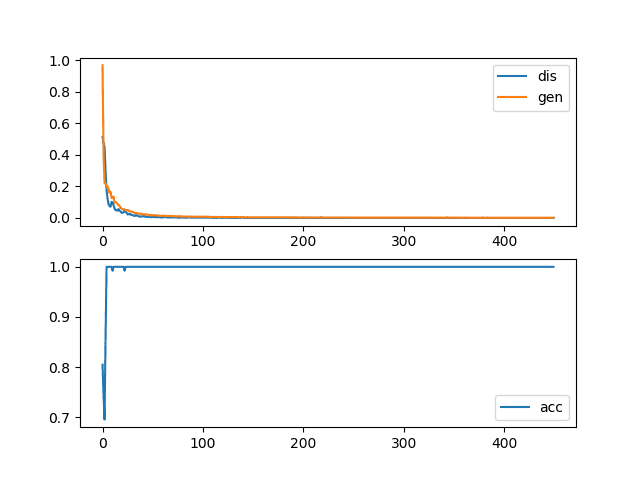

Enfin, l'examen des échantillons d'images générées montre clairement pourquoi le discriminateur est si efficace.

Les échantillons d'images générées à chaque époque sont de très basse qualité, montrant du statique, avec peut-être une faible figure de huit en arrière-plan.

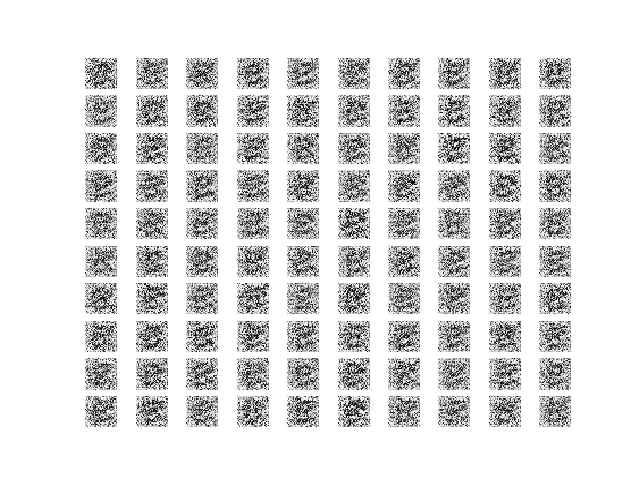

Il est utile de voir un autre exemple de ce type d'échec.

Dans ce cas, la configuration de l'algorithme d'optimisation Adam peut être modifiée pour utiliser les paramètres par défaut, ce qui rend les mises à jour des modèles agressives et empêche le processus d'entraînement de trouver un point d'équilibre entre l'entraînement des deux modèles.

Par exemple, le discriminateur peut être compilé comme suit :

In [ ]:
...
# compile model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Et le modèle GAN composite peut être compilé comme suit :

In [ ]:
...
# compile model
model.compile(loss='binary_crossentropy', optimizer='adam')

In [3]:
# example of training an unstable gan for generating a handwritten digit
from os import makedirs
from numpy import expand_dims
from numpy import zeros
from numpy import ones
from numpy.random import randn
from numpy.random import randint
from keras.datasets.mnist import load_data
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import Conv2DTranspose
from keras.layers import LeakyReLU
from keras.initializers import RandomNormal
from matplotlib import pyplot

# define the standalone discriminator model
def define_discriminator(in_shape=(28,28,1)):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# downsample to 14x14
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init, input_shape=in_shape))
	model.add(LeakyReLU(alpha=0.2))
	# downsample to 7x7
	model.add(Conv2D(64, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# classifier
	model.add(Flatten())
	model.add(Dense(1, activation='sigmoid'))
	# compile model
	model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
	return model

# define the standalone generator model
def define_generator(latent_dim):
	# weight initialization
	init = RandomNormal(stddev=0.02)
	# define model
	model = Sequential()
	# foundation for 7x7 image
	n_nodes = 128 * 7 * 7
	model.add(Dense(n_nodes, kernel_initializer=init, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((7, 7, 128)))
	# upsample to 14x14
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 28x28
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same', kernel_initializer=init))
	model.add(LeakyReLU(alpha=0.2))
	# output 28x28x1
	model.add(Conv2D(1, (7,7), activation='tanh', padding='same', kernel_initializer=init))
	return model

# define the combined generator and discriminator model, for updating the generator
def define_gan(generator, discriminator):
	# make weights in the discriminator not trainable
	discriminator.trainable = False
	# connect them
	model = Sequential()
	# add generator
	model.add(generator)
	# add the discriminator
	model.add(discriminator)
	# compile model
	model.compile(loss='binary_crossentropy', optimizer='adam')
	return model

# load mnist images
def load_real_samples():
	# load dataset
	(trainX, trainy), (_, _) = load_data()
	# expand to 3d, e.g. add channels
	X = expand_dims(trainX, axis=-1)
	# select all of the examples for a given class
	selected_ix = trainy == 8
	X = X[selected_ix]
	# convert from ints to floats
	X = X.astype('float32')
	# scale from [0,255] to [-1,1]
	X = (X - 127.5) / 127.5
	return X

# select real samples
def generate_real_samples(dataset, n_samples):
	# choose random instances
	ix = randint(0, dataset.shape[0], n_samples)
	# select images
	X = dataset[ix]
	# generate class labels
	y = ones((n_samples, 1))
	return X, y

# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
	# generate points in the latent space
	x_input = randn(latent_dim * n_samples)
	# reshape into a batch of inputs for the network
	x_input = x_input.reshape(n_samples, latent_dim)
	return x_input

# use the generator to generate n fake examples, with class labels
def generate_fake_samples(generator, latent_dim, n_samples):
	# generate points in latent space
	x_input = generate_latent_points(latent_dim, n_samples)
	# predict outputs
	X = generator.predict(x_input)
	# create class labels
	y = zeros((n_samples, 1))
	return X, y

# generate samples and save as a plot and save the model
def summarize_performance(step, g_model, latent_dim, n_samples=100):
	# prepare fake examples
	X, _ = generate_fake_samples(g_model, latent_dim, n_samples)
	# scale from [-1,1] to [0,1]
	X = (X + 1) / 2.0
	# plot images
	for i in range(10 * 10):
		# define subplot
		pyplot.subplot(10, 10, 1 + i)
		# turn off axis
		pyplot.axis('off')
		# plot raw pixel data
		pyplot.imshow(X[i, :, :, 0], cmap='gray_r')
	# save plot to file
	pyplot.savefig('results_opt/generated_plot_%03d.png' % (step+1))
	pyplot.close()
	# save the generator model
	g_model.save('results_opt/model_%03d.h5' % (step+1))

# create a line plot of loss for the gan and save to file
def plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist):
	# plot loss
	pyplot.subplot(2, 1, 1)
	pyplot.plot(d1_hist, label='d-real')
	pyplot.plot(d2_hist, label='d-fake')
	pyplot.plot(g_hist, label='gen')
	pyplot.legend()
	# plot discriminator accuracy
	pyplot.subplot(2, 1, 2)
	pyplot.plot(a1_hist, label='acc-real')
	pyplot.plot(a2_hist, label='acc-fake')
	pyplot.legend()
	# save plot to file
	pyplot.savefig('results_opt/plot_line_plot_loss.png')
	pyplot.close()

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=10, n_batch=128):
    # calculate the number of batches per epoch
    bat_per_epo = int(dataset.shape[0] / n_batch)
    # calculate the total iterations based on batch and epoch
    n_steps = bat_per_epo * n_epochs
    # calculate the number of samples in half a batch
    half_batch = int(n_batch / 2)
    # prepare lists for storing stats each iteration
    d1_hist, d2_hist, g_hist, a1_hist, a2_hist = list(), list(), list(), list(), list()
    # manually enumerate epochs
    for i in range(n_steps):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator model weights
        d_loss1, d_acc1 = d_model.train_on_batch(X_real, y_real)
        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
        # update discriminator model weights
        d_loss2, d_acc2 = d_model.train_on_batch(X_fake, y_fake)
        # prepare points in latent space as input for the generator
        X_gan = generate_latent_points(latent_dim, n_batch)
        # create inverted labels for the fake samples
        y_gan = ones((n_batch, 1))
        # update the generator via the discriminator's error
        g_loss = gan_model.train_on_batch(X_gan, y_gan)

        # Make sure the losses are scalar (not lists)
        if isinstance(g_loss, list):
            g_loss = g_loss[0]
        if isinstance(d_loss1, list):
            d_loss1 = d_loss1[0]
        if isinstance(d_loss2, list):
            d_loss2 = d_loss2[0]

        # summarize loss on this batch
        print('>%d, d1=%.3f, d2=%.3f g=%.3f, a1=%d, a2=%d' %
              (i+1, d_loss1, d_loss2, g_loss, int(100*d_acc1), int(100*d_acc2)))

        # record history
        d1_hist.append(d_loss1)
        d2_hist.append(d_loss2)
        g_hist.append(g_loss)
        a1_hist.append(d_acc1)
        a2_hist.append(d_acc2)

        # evaluate the model performance every 'epoch'
        if (i+1) % bat_per_epo == 0:
            summarize_performance(i, g_model, latent_dim)
    plot_history(d1_hist, d2_hist, g_hist, a1_hist, a2_hist)

# make folder for results
makedirs('results_opt', exist_ok=True)
# size of the latent space
latent_dim = 50
# create the discriminator
discriminator = define_discriminator()
# create the generator
generator = define_generator(latent_dim)
# create the gan
gan_model = define_gan(generator, discriminator)
# load image data
dataset = load_real_samples()
print(dataset.shape)
# train model
train(generator, discriminator, gan_model, dataset, latent_dim)

(5851, 28, 28, 1)
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  
>1, d1=0.687, d2=0.690 g=0.690, a1=76, a2=42
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>2, d1=0.689, d2=0.692 g=0.692, a1=56, a2=42
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>3, d1=0.691, d2=0.694 g=0.694, a1=50, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>4, d1=0.693, d2=0.697 g=0.697, a1=47, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>5, d1=0.695, d2=0.700 g=0.700, a1=47, a2=42
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>6, d1=0.699, d2=0.704 g=0.704, a1=46, a2=42
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>7, d1=0.703, d2=0.707 g=0.707, a1=44, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>8, d1=0.706, d2=0.710 g=0.710, a1=44, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>9, d1=0.708, d2=0.712 g=0.712, a1=43, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>10, d1=0.710, d2=0.713 g=0.713, a1=43, a2=41
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>11, d1=0.712, d2=0.715 g=0.715, a1=42, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>12, d1=0.714, d2=0.716 g=0.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>46, d1=0.738, d2=0.739 g=0.739, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>47, d1=0.738, d2=0.739 g=0.739, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>48, d1=0.739, d2=0.740 g=0.740, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>49, d1=0.739, d2=0.740 g=0.740, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>50, d1=0.740, d2=0.741 g=0.741, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>51, d1=0.740, d2=0.741 g=0.741, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>52, d1=0.741, d2=0.742 g=0.742, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>53, d1=0.741, d2=0.742 g=0.742, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>54, d1=0.741, d2=0.742 g=0.742, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>55, d1=0.742, d2=0.743 g=0.743, a1=41, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>56, d1=0.742, d2=0.743 g=0.743, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>57, d1=0.743, d2=0.743 g=0.743, a1=41

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>91, d1=0.752, d2=0.752 g=0.752, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>92, d1=0.752, d2=0.752 g=0.752, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>93, d1=0.752, d2=0.752 g=0.752, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>94, d1=0.752, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>95, d1=0.752, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>96, d1=0.752, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>97, d1=0.753, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>98, d1=0.753, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>99, d1=0.753, d2=0.753 g=0.753, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>100, d1=0.753, d2=0.754 g=0.754, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>101, d1=0.753, d2=0.754 g=0.754, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>102, d1=0.753, d2=0.754 g=0.754, a1

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>136, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>137, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>138, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>139, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>140, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>141, d1=0.758, d2=0.758 g=0.758, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>142, d1=0.758, d2=0.759 g=0.759, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>143, d1=0.758, d2=0.759 g=0.759, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>144, d1=0.758, d2=0.759 g=0.759, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>145, d1=0.759, d2=0.759 g=0.759, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>146, d1=0.759, d2=0.759 g=0.759, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>147, d1=0.759, d2=0.759 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>181, d1=0.761, d2=0.761 g=0.761, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>182, d1=0.761, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>183, d1=0.761, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>184, d1=0.761, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>185, d1=0.761, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>186, d1=0.761, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>187, d1=0.762, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>188, d1=0.762, d2=0.762 g=0.762, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>189, d1=0.762, d2=0.762 g=0.762, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>190, d1=0.762, d2=0.762 g=0.762, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>191, d1=0.762, d2=0.762 g=0.762, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>192, d1=0.762, d2=0.762 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>226, d1=0.763, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>227, d1=0.763, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>228, d1=0.763, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>229, d1=0.763, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>230, d1=0.764, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>231, d1=0.764, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>232, d1=0.764, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
>233, d1=0.764, d2=0.764 g=0.764, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>234, d1=0.764, d2=0.764 g=0.764, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>235, d1=0.764, d2=0.764 g=0.764, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>236, d1=0.764, d2=0.764 g=0.764, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>237, d1=0.764, d2=0.764 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
>271, d1=0.765, d2=0.765 g=0.765, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>272, d1=0.765, d2=0.765 g=0.765, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>273, d1=0.765, d2=0.765 g=0.765, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>274, d1=0.765, d2=0.765 g=0.765, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>275, d1=0.765, d2=0.765 g=0.765, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>276, d1=0.765, d2=0.765 g=0.765, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>277, d1=0.765, d2=0.766 g=0.766, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>278, d1=0.765, d2=0.766 g=0.766, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>279, d1=0.765, d2=0.766 g=0.766, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>280, d1=0.765, d2=0.766 g=0.766, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>281, d1=0.765, d2=0.766 g=0.766, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>282, d1=0.766, d2=0.766 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>316, d1=0.766, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>317, d1=0.766, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>318, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>319, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>320, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>321, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>322, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>323, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>324, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>325, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
>326, d1=0.767, d2=0.767 g=0.767, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>327, d1=0.767, d2=0.767 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>361, d1=0.767, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>362, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>363, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>364, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>365, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>366, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>367, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>368, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>369, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>370, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>371, d1=0.768, d2=0.768 g=0.768, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>372, d1=0.768, d2=0.768 g=

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>406, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>407, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>408, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>409, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>410, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>411, d1=0.768, d2=0.768 g=0.768, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>412, d1=0.768, d2=0.769 g=0.769, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>413, d1=0.768, d2=0.769 g=0.769, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
>414, d1=0.768, d2=0.769 g=0.769, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>415, d1=0.768, d2=0.769 g=0.769, a1=40, a2=39
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>416, d1=0.768, d2=0.769 g=0.769, a1=40, a2=40
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
>417, d1=0.768, d2=0.769 g=

Comme nous nous y attendions, la perte du discriminateur chute rapidement à une valeur proche de zéro, où elle reste, et la précision de classification du discriminateur sur les exemples réels et faux reste à 100 %.

Le graphique montre que ce changement fait plonger la perte du discriminateur à une valeur proche de zéro et y rester. Une différence importante dans ce cas est que la perte du générateur augmente rapidement et continue d'augmenter pendant toute la durée de l'entraînement.

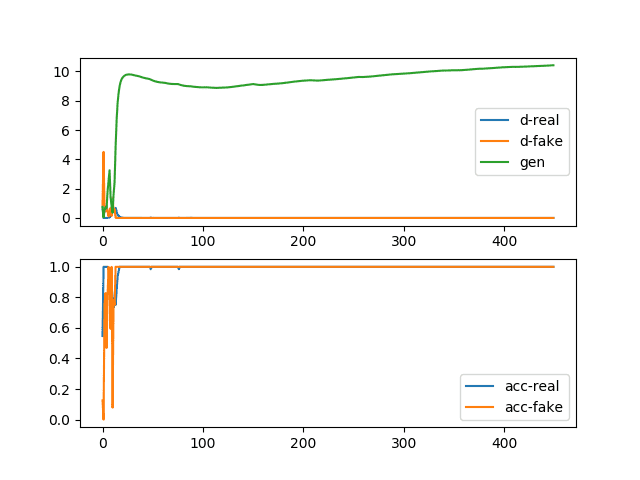

Nous pouvons résumer les propriétés d'un échec de convergence comme suit :

*    La perte du discriminateur doit rapidement diminuer à une valeur proche de zéro, où elle reste pendant l'entraînement.
*    La perte du générateur doit soit diminuer jusqu'à zéro, soit continuer à diminuer pendant l'entraînement.
*    Le générateur est censé produire des images de très basse qualité qui sont facilement identifiées comme fausses par le discriminateur.